# Shared Social Responsibility

A field experiment has been conducted at an amusement park. Participants rode a roller coaster and were photographed during the ride. Afterward, each rider chose whether or not to purchase a print(s) of the photograph that was taken. The experiment itself placed each rider into one of four conditions:

- $12.95 flat-rate price, i.e., **FR**
- $12.95 flat-rate price with 50% of revenue going to charity, i.e., **FR Charity**
- Name Your Own Price, i.e., **NYOP**
- Name Your Own Price with 50% of revenue going to charity, i.e., **NYOP Charity**

The charitable partner was a nationally recognized patient-support foundation. Two datasets from the experiment have been provided to you in comma-delimited files for your analysis.


## Datasets

### Description of “Sales.csv”

This dataset contains the number of photos sold, the number of riders, and the total merchandise revenues for each of the four conditions. Each condition was in place for 2 days (two rows of data) except for the last condition, **NYOP Charity**, which was in place for 3 days.

#### Variables

- **Condition** = A factor with four levels, matching each of the possibilities described above: `FR`, `FR Charity`, `NYOP`, and `NYOP Charity`
- **NumberSold** = The total number of photos purchased by consumers on a given day under the condition described
- **Riders** = The total number of riders placed into the condition on a given day under the condition described
- **MerchandiseRevenues** = Ancillary revenues related to merchandise purchased by riders at a location adjacent to the ride. Revenues are in US dollars.

### Description of “NYOP.csv”

This dataset contains more specific information related to the **NYOP** and **NYOP Charity** conditions. Each row represents the purchasing behavior of a rider who made a purchase. Information on the condition of the rider, the number of photos purchased, and the price chosen by the rider have been collected.

#### Variables

- **Condition** = A factor with two levels, `NYOP` and `NYOP Charity`, capturing any rider who was in one of the two Name Your Own Price conditions
- **Number** = The total number of photos purchased by a given rider
- **Price** = The price chosen by the rider and paid in US dollars.


## Analysis

You have been asked to carefully study the results from this field experiment to answer several questions your company has about the effectiveness of these different pricing strategies. In particular, you have been asked to write a memo that summarizes your findings. Below, we provide some guiding questions to help you in your exploration.

_Do these calculations without calling built-in t-test functions_


In [17]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import pyrsm as rsm
import polars as pl

sales = pd.read_csv("Sales.csv")
nyop = pd.read_csv("NYOP.csv")

a. What are appropriate null and alternative hypothesis to compare population proportions?


In [9]:
# Author: Hung-Che Wang
fr = sales[sales["Condition"] == "FR"]
fr_charity = sales[sales["Condition"] == "FR Charity"]

fr_sold = fr["NumberSold"].sum()
fr_riders = fr["Riders"].sum()
fr_charity_sold = fr_charity["NumberSold"].sum()
fr_charity_riders = fr_charity["Riders"].sum()

print("FR:", fr_sold, fr_riders)
print("FR Charity:", fr_charity_sold, fr_charity_riders)

FR: 140 28224
FR Charity: 180 30592


Let $p_{FR}$ be the true proportion of riders who buy a photo under the FR condition, and $p_{FRC}$ the true proportion under the FR Charity condition.

- $H_0: p_{FR} = p_{FRC}$ (the purchase proportions are the same)
- $H_a: p_{FR} \neq p_{FRC}$ (the purchase proportions are different)


In [10]:
# Author: Hung-Che Wang
p1 = fr_sold / fr_riders
p2 = fr_charity_sold / fr_charity_riders
n1 = fr_riders
n2 = fr_charity_riders

print("p1 =", p1)
print("p2 =", p2)
print("n1 =", n1)
print("n2 =", n2)

p1 = 0.00496031746031746
p2 = 0.005883891213389121
n1 = 28224
n2 = 30592


b. The appropriate test statistic for the difference between two population proportions is given by

$$
\frac{\bar{p}_1-\bar{p}_2}
{\sqrt{\frac{\bar{p}_1(1-\bar{p}_1)}{n_1}+\frac{\bar{p}_2(1-\bar{p}_2)}{n_2}}},
$$

and with the large number of samples you can go ahead and assume the sampling distribution is normally distributed. Is the difference significant at the 5% level?


We compare the two purchase proportions using the test statistic

$$z=\frac{\bar p_1-\bar p_2}{\sqrt{\frac{\bar p_1(1-\bar p_1)}{n_1}+\frac{\bar p_2(1-\bar p_2)}{n_2}}}$$

where $\bar p_1$ and $\bar p_2$ are the purchase proportions (photos sold divided by riders) of FR and FR Charity, and $n_1$, $n_2$ are the numbers of riders. Because the samples are large, we treat $z$ as standard normal, so at the 5% level (two-sided) we reject $H_0$ if $|z| > 1.96$.


In [11]:
# Author: Hung-Che Wang
part1 = p1 * (1 - p1) / n1
part2 = p2 * (1 - p2) / n2
se = (part1 + part2) ** 0.5

print("part1 =", part1)
print("part2 =", part2)
print("se =", se)

part1 = 1.748764424252526e-07
part2 = 1.912026359040966e-07
se = 0.0006050446911835102


In [12]:
# Author: Hung-Che Wang
diff = p1 - p2
z = diff / se

print("diff =", diff)
print("z =", z)

diff = -0.000923573753071661
z = -1.5264554280529021


In [13]:
# Author: Hung-Che Wang
z_critical = 1.96
significant = abs(z) > z_critical

print("z =", z)
print("critical value =", z_critical)
print("is |z| bigger than the critical value?", significant)

z = -1.5264554280529021
critical value = 1.96
is |z| bigger than the critical value? False


**Result.** The purchase proportion is about 0.496% under FR and 0.588% under FR Charity. The test statistic is $z \approx -1.53$. Since $|z| = 1.53 < 1.96$, the difference is **not significant** at the 5% level, so we fail to reject $H_0$.


In [15]:
# Author: Hung-Che Wang
p_value = 2 * stats.norm.sf(abs(z))
print("p-value =", p_value)

p-value = 0.12689648269385964


c. What is the p-value associated with the test statistic?


The two-sided p-value associated with $z \approx -1.53$ is **about 0.127**.


d. Interpret what this p-value means.


The p-value is the probability of seeing a difference in purchase proportions at least as large as the one we observed (in either direction), assuming $H_0$ is true, that is, assuming the charity component has no effect on the purchase rate. Here, if the charity component truly had no effect, we would still see a gap this large about 12.7% of the time just from random variation in who rides and who buys. Because 12.7% is above the 5% threshold, this is not unusual enough to reject $H_0$. With a flat price, we do not have convincing evidence that the charity component changes the purchase proportion. This does not prove there is no effect; it only means the data cannot tell an effect apart from chance.


### NYOP Pricing

When considering the two NYOP pricing conditions, **NYOP** and **NYOP Charity**, is there a difference between the proportion of purchases? Repeat steps (a)-(d) as above.

_Use any built-in functions for this portion of the analysis_

a. Load “NYOP.csv”. Create a variable called `UnitPrice` which takes the variable, `Price`, and divides it by `Number`. After doing so, next change the type of the variable, `Number`, to a factor variable.


In [20]:
# Author: Haolin Zhang
nyop["UnitPrice"] = nyop["Price"] / nyop["Number"]
nyop["Number"] = nyop["Number"].astype("category")

b. Visualize both `Price` and `UnitPrice` against the factor variable, `Number` by creating box plots and interpreting them.


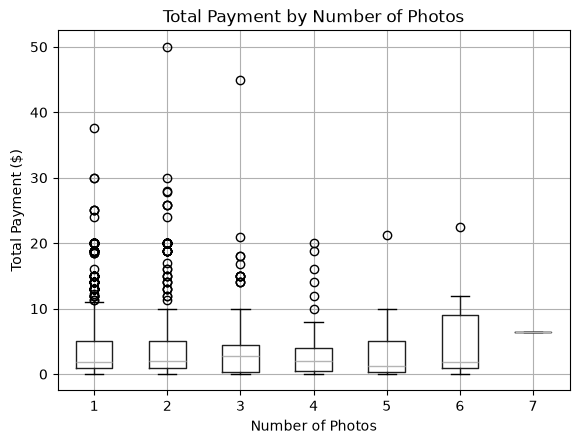

In [18]:
# Author: Haolin Zhang
nyop.boxplot(column="Price", by="Number")

plt.title("Total Payment by Number of Photos")
plt.suptitle("")
plt.xlabel("Number of Photos")
plt.ylabel("Total Payment ($)")
plt.show()

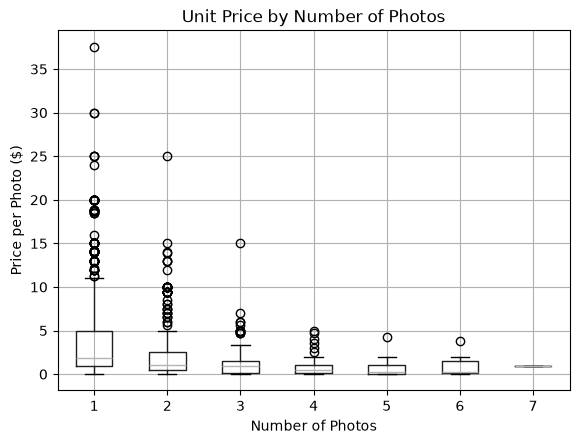

In [21]:
# Author: Haolin Zhang
nyop.boxplot(column="UnitPrice", by="Number")

plt.title("Unit Price by Number of Photos")
plt.suptitle("")
plt.xlabel("Number of Photos")
plt.ylabel("Price per Photo ($)")
plt.show()

The box plots show that total payment (`Price`) does not increase proportionally with the number of photos purchased. As a result, the price per photo (`UnitPrice`) generally decreases as customers purchase more photos.


c. Determine the average unit purchase price for both the **NYOP** and the **NYOP Charity** conditions. Does the difference seem small or substantial? Formulate a statistical test to determine if these two average unit prices are different.


In [23]:
# Author: Haolin Zhang
nyop_group = nyop[nyop["Condition"] == "NYOP"]
charity_group = nyop[nyop["Condition"] == "NYOP Charity"]

mean1 = nyop_group["UnitPrice"].mean()
mean2 = charity_group["UnitPrice"].mean()

print("NYOP average unit price:", round(mean1, 4))
print("Charity average unit price:", round(mean2, 4))
print("Difference:", round(mean2 - mean1, 4))

NYOP average unit price: 1.0404
Charity average unit price: 5.6805
Difference: 4.64


d. What are your null and alternative hypotheses?


- $H_0$: The population mean unit prices are equal
- $H_a$: The population mean unit prices are different


e. Use the pyrsm library to perform the test computation (**Compare means**). What can you conclude? What is the likelihood you have made either a Type I or Type II error based on your conclusion?


In [24]:
# Author: Haolin Zhang
nyop_for_test = pl.from_pandas(nyop[["Condition", "UnitPrice"]])

mean_test = rsm.basics.compare_means(
    data=nyop_for_test, var1="Condition", var2="UnitPrice"
)

mean_test.summary()

Pairwise mean comparisons (t-test)
Data      : Not provided
Variables : Condition, UnitPrice
Samples   : independent
Confidence: 0.95
Adjustment: None

┌──────────────┬──────┬──────┬───────────┬───────┬───────┬───────┐
│ Condition    ┆ mean ┆ n    ┆ n_missing ┆ sd    ┆ se    ┆ me    │
╞══════════════╪══════╪══════╪═══════════╪═══════╪═══════╪═══════╡
│ NYOP         ┆ 1.04 ┆ 1641 ┆ 0         ┆ 1.305 ┆ 0.032 ┆ 0.063 │
│ NYOP Charity ┆ 5.68 ┆ 1457 ┆ 0         ┆ 4.67  ┆ 0.122 ┆ 0.24  │
└──────────────┴──────┴──────┴───────────┴───────┴───────┴───────┘
┌─────────────────────┬────────────────────────────────┬───────┬─────────┬─────┐
│ Null hyp.           ┆ Alt. hyp.                      ┆ diff  ┆ p.value ┆     │
╞═════════════════════╪════════════════════════════════╪═══════╪═════════╪═════╡
│ NYOP = NYOP Charity ┆ NYOP not equal to NYOP Charity ┆ -4.64 ┆ < .001  ┆ *** │
└─────────────────────┴────────────────────────────────┴───────┴─────────┴─────┘

Signif. codes:  0 '***' 0.001 '**' 0.01 

The t-test gives a p-value below 0.001, so we reject the null hypothesis at the 5% significance level. There is strong evidence that the population mean unit prices differ. NYOP Charity purchasers paid an average of $5.68 per photo, compared with $1.04 for NYOP purchasers.


f. Use filtering to investigate the difference in means for people that purchased 1 picture. Similarly, do the analysis for the group that purchased 6 pictures. Discuss your observations.


In [25]:
# Author: Haolin Zhang
one_photo = nyop[nyop["Number"] == 1]

display(one_photo.groupby("Condition")["UnitPrice"].agg(["count", "mean", "std"]))

one_photo_for_test = pl.from_pandas(one_photo[["Condition", "UnitPrice"]])

one_photo_test = rsm.basics.compare_means(
    data=one_photo_for_test, var1="Condition", var2="UnitPrice"
)

one_photo_test.summary()

,count,mean,std
Condition,,,
NYOP,1162,1.176523,1.432111
NYOP Charity,1203,5.941155,4.830262


Pairwise mean comparisons (t-test)
Data      : Not provided
Variables : Condition, UnitPrice
Samples   : independent
Confidence: 0.95
Adjustment: None

┌──────────────┬───────┬──────┬───────────┬───────┬───────┬───────┐
│ Condition    ┆ mean  ┆ n    ┆ n_missing ┆ sd    ┆ se    ┆ me    │
╞══════════════╪═══════╪══════╪═══════════╪═══════╪═══════╪═══════╡
│ NYOP         ┆ 1.177 ┆ 1162 ┆ 0         ┆ 1.432 ┆ 0.042 ┆ 0.082 │
│ NYOP Charity ┆ 5.941 ┆ 1203 ┆ 0         ┆ 4.83  ┆ 0.139 ┆ 0.273 │
└──────────────┴───────┴──────┴───────────┴───────┴───────┴───────┘
┌─────────────────────┬────────────────────────────────┬────────┬─────────┬─────┐
│ Null hyp.           ┆ Alt. hyp.                      ┆ diff   ┆ p.value ┆     │
╞═════════════════════╪════════════════════════════════╪════════╪═════════╪═════╡
│ NYOP = NYOP Charity ┆ NYOP not equal to NYOP Charity ┆ -4.765 ┆ < .001  ┆ *** │
└─────────────────────┴────────────────────────────────┴────────┴─────────┴─────┘

Signif. codes:  0 '***' 0.001

In [26]:
# Author: Haolin Zhang
six_photos = nyop[nyop["Number"] == 6]

display(six_photos.groupby("Condition")["UnitPrice"].agg(["count", "mean", "std"]))

six_photos_for_test = pl.from_pandas(six_photos[["Condition", "UnitPrice"]])

six_photos_test = rsm.basics.compare_means(
    data=six_photos_for_test, var1="Condition", var2="UnitPrice"
)

six_photos_test.summary()

,count,mean,std
Condition,,,
NYOP,6,0.495,0.615232
NYOP Charity,3,1.970,1.795188


Pairwise mean comparisons (t-test)
Data      : Not provided
Variables : Condition, UnitPrice
Samples   : independent
Confidence: 0.95
Adjustment: None

┌──────────────┬───────┬───┬───────────┬───────┬───────┬───────┐
│ Condition    ┆ mean  ┆ n ┆ n_missing ┆ sd    ┆ se    ┆ me    │
╞══════════════╪═══════╪═══╪═══════════╪═══════╪═══════╪═══════╡
│ NYOP         ┆ 0.495 ┆ 6 ┆ 0         ┆ 0.615 ┆ 0.251 ┆ 0.646 │
│ NYOP Charity ┆ 1.97  ┆ 3 ┆ 0         ┆ 1.795 ┆ 1.036 ┆ 4.459 │
└──────────────┴───────┴───┴───────────┴───────┴───────┴───────┘
┌─────────────────────┬────────────────────────────────┬────────┬─────────┬───┐
│ Null hyp.           ┆ Alt. hyp.                      ┆ diff   ┆ p.value ┆   │
╞═════════════════════╪════════════════════════════════╪════════╪═════════╪═══╡
│ NYOP = NYOP Charity ┆ NYOP not equal to NYOP Charity ┆ -1.475 ┆ 0.288   ┆   │
└─────────────────────┴────────────────────────────────┴────────┴─────────┴───┘

Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 

For customers who purchased one photo, the average unit price was $1.18 under NYOP and $5.94 under NYOP Charity. The p-value is below 0.001, so we reject the null hypothesis and conclude that the population mean unit prices differ. For customers who purchased six photos, the average unit price was $0.495 under NYOP and $1.97 under NYOP Charity. However, the p-value is 0.288, so we fail to reject the null hypothesis at the 5% level. Although the charity group paid more on average in both cases, the six-photo group contains only 6 NYOP customers and 3 charity customers. This small sample makes the comparison less precise. The nonsignificant result does not prove that the population means are equal.


g. If you do the analysis by hand for the group that purchased 6 pictures are your results the same as those produced above? Why or Why not?


In [28]:
# Author: Haolin Zhang
six_nyop = six_photos[six_photos["Condition"] == "NYOP"]
six_charity = six_photos[six_photos["Condition"] == "NYOP Charity"]

n1 = len(six_nyop)
n2 = len(six_charity)

mean1 = six_nyop["UnitPrice"].mean()
mean2 = six_charity["UnitPrice"].mean()

var1 = six_nyop["UnitPrice"].var()
var2 = six_charity["UnitPrice"].var()

print("Sample sizes:", n1, n2)
print("Means:", mean1, mean2)
print("Variances:", var1, var2)

part1 = var1 / n1
part2 = var2 / n2
se = (part1 + part2) ** 0.5
t = (mean1 - mean2) / se
numerator = (part1 + part2) ** 2
denominator = part1**2 / (n1 - 1) + part2**2 / (n2 - 1)

df = numerator / denominator
p_value = 2 * stats.t.sf(abs(t), df)

print("Standard error:", round(se, 6))
print("t:", round(t, 6))
print("Degrees of freedom:", round(df, 6))
print("p-value:", round(p_value, 6))

Sample sizes: 6 3
Means: 0.49499999999999994 1.97
Variances: 0.37851 3.2226999999999997
Standard error: 1.066451
t: -1.383092
Degrees of freedom: 2.238712
p-value: 0.288411


The results are the same because both the hand calculation and pyrsm use Welch’s t-test. They use the same data and formulas to calculate the t-value, degrees of freedom, and p-value.


### Economics

a. The unit cost of making a photo is $1.20. Compute the average daily profit under each of the four pricing strategies.


In [2]:
# Author: Zixiao Ma
# select the data under specific conditions
fr = sales[sales["Condition"] == "FR"]
fr_charity = sales[sales["Condition"] == "FR Charity"]
nyop_sales = sales[sales["Condition"] == "NYOP"]
nyop_charity_sales = sales[sales["Condition"] == "NYOP Charity"]
nyop_purchases = nyop[nyop["Condition"] == "NYOP"]
nyop_charity_purchases = nyop[nyop["Condition"] == "NYOP Charity"]
# set the price, cost, and donation share
flat_price = 12.95
photo_cost = 1.20
donation_share = 0.50
# calculate the average daily profit for each condition
# for FR
fr_revenue = flat_price * fr["NumberSold"].sum()
fr_cost = fr["NumberSold"].sum() * photo_cost
fr_profit = (fr_revenue - fr_cost) / 2
# for FR charity
fr_charity_revenue = fr_charity["NumberSold"].sum() * flat_price
fr_charity_cost = fr_charity["NumberSold"].sum() * photo_cost
fr_charity_donation = fr_charity_revenue * donation_share
fr_charity_profit = (fr_charity_revenue - fr_charity_cost - fr_charity_donation) / 2
# for NYOP
nyop_revenue = nyop_purchases["Price"].sum()
nyop_cost = nyop_sales["NumberSold"].sum() * photo_cost
nyop_profit = (nyop_revenue - nyop_cost) / 2
# NYOP charity
nyop_charity_revenue = nyop_charity_purchases["Price"].sum()
nyop_charity_cost = nyop_charity_sales["NumberSold"].sum() * photo_cost
nyop_charity_donation = nyop_charity_revenue * donation_share
nyop_charity_profit = (
    nyop_charity_revenue - nyop_charity_cost - nyop_charity_donation
) / 3
# print the result
results = pd.DataFrame(
    {
        "Strategy": ["FR", "FR Charity", "NYOP", "NYOP Charity"],
        "Park Daily Profit": [
            fr_profit,
            fr_charity_profit,
            nyop_profit,
            nyop_charity_profit,
        ],
    }
)
results.sort_values("Park Daily Profit", ascending=False).round(2)
# table format
results.style.format({"Park Daily Profit": "${:,.2f}"})

,Strategy,Park Daily Profit
0,FR,$822.50
1,FR Charity,$474.75
2,NYOP,$-334.10
3,NYOP Charity,$885.52


b. Which strategy is the most profitable? What is the ranking of the strategies in terms of profits?


The NYOP Charity strategy generates the highest daily profit at ＄885.52, while the NYOP strategy alone suffers a loss of ＄334.10. The FR strategy earns the second-highest profit of ＄822.50. However, the FR Charity strategy only earns ＄474.75. This is much lower than the FR profit. This implies that the charity component has opposite effects depending on the base strategy. It turns the losing NYOP model into a winner. However, it hurts the already profitable FR model. The result suggests that charity appeals work best when paired with flexible pricing (NYOP), likely because it encourages customers to pay more voluntarily.


c. Now think about the additional value created by the **FR Charity** and **NYOP Charity** conditions. Rather than focusing only on profits to the theme park, let’s talk about total profits to society which should include both the theme park and the charity that benefits. What is the ranking of societal profits in this case?


In [6]:
# Author: Zixiao Ma
# calculate total and daily society profit
# FR charity
fr_charity_daily_society = fr_charity_donation / 2 + fr_charity_profit
# NYOP charity
nyop_charity_daily_society = nyop_charity_donation / 3 + nyop_charity_profit
# print the result
results = pd.DataFrame(
    {
        "Strategy": ["FR", "NYOP", "FR Charity", "NYOP Charity"],
        "Daily Society Profit": [
            fr_profit,
            nyop_profit,
            fr_charity_daily_society,
            nyop_charity_daily_society,
        ],
    }
)
results["Annual Society Profit"] = results["Daily Society Profit"] * 365
results_1 = results.sort_values("Daily Society Profit", ascending=False).round(2)

display(
    results_1.style.format(
        {"Daily Society Profit": "${:,.2f}", "Annual Society Profit": "${:,.2f}"}
    )
)

,Strategy,Daily Society Profit,Annual Society Profit
3,NYOP Charity,"$2,488.24","$908,206.38"
2,FR Charity,"$1,057.50","$385,987.50"
0,FR,$822.50,"$300,212.50"
1,NYOP,$-334.10,"$-121,946.50"


When we look at total societal profit, it is observed that the strategy including charity generates a higher annual social profit than those without charity. The NYOP Charity strategy is by far the best for society because it earns the highest annual profit at ＄908,206.38. Using the NYOP still results in a loss of $121,946.50. Notably, adding charity to the FR strategy creates more total value for society (＄385,987.50) than the standard FR strategy (＄300,212.50), even though the park makes less money on its own. This suggests that the charity component adds significant value to the community.


d. How much additional societal profit does the leading strategy generate over the others over the entire year (assume 365 days)?


In [5]:
# Author: Zixiao Ma
# identify the leading daily profit
leading_daily_profit = results["Daily Society Profit"].max()
results["Additional Annual Profit vs. Leader"] = (
    leading_daily_profit - results["Daily Society Profit"]
) * 365
# sort result by daily society profit and only keep additional profit
results_2 = results.sort_values("Daily Society Profit", ascending=False).round(2)[
    ["Strategy", "Additional Annual Profit vs. Leader"]
]

display(results_2.style.format({"Additional Annual Profit vs. Leader": "${:,.2f}"}))


,Strategy,Additional Annual Profit vs. Leader
3,NYOP Charity,$0.00
2,FR Charity,"$522,218.88"
0,FR,"$607,993.88"
1,NYOP,"$1,030,152.88"


Compared to the FR Charity strategy, the leading strategy(NYOP Charity) creates an additional social profit of ＄522,218.88. It also generates ＄607,993.88 more than the FR strategy and ＄1,030,152.88 more than the NYOP strategy. In summary, the NYOP Charity strategy is extremely powerful. It turns the worst-performing model (NYOP) into the best-performing model, creating over $1 million more value for society than the NYOP strategy alone.


e. Are merchandise sales a concern?


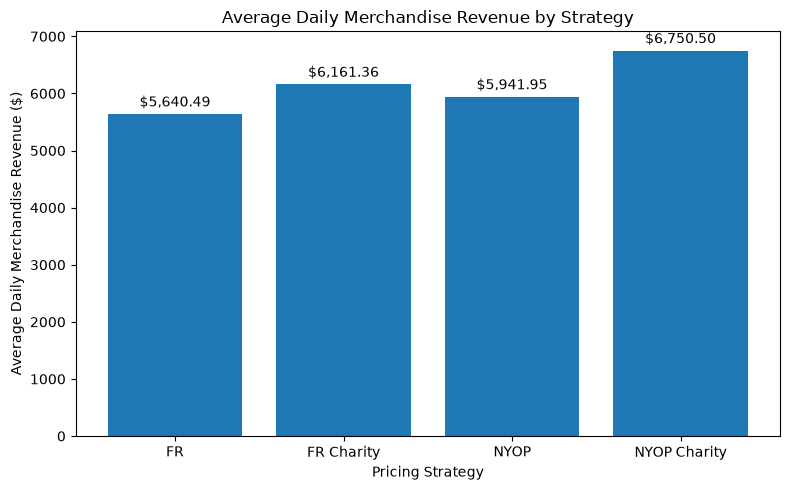

In [7]:
# Author: Zixiao Ma
# calculate average daily merchandise revenue for four strategies
merchandise_daily_avg = sales.groupby("Condition")["MerchandiseRevenues"].mean()
# create a bar plot
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(merchandise_daily_avg.index, merchandise_daily_avg.values)

ax.set_title("Average Daily Merchandise Revenue by Strategy")
ax.set_xlabel("Pricing Strategy")
ax.set_ylabel("Average Daily Merchandise Revenue ($)")
ax.bar_label(
    bars, labels=[f"${v:,.2f}" for v in merchandise_daily_avg.values], padding=3
)

plt.tight_layout()
plt.show()


In [8]:
# Author: Zixiao Ma
# conduct a one-way ANOVA to check if difference is significant
# H0: The average daily merchandise revenue of the four strategies is the same.
# Ha: At least one of the daily merchandise revenues is different.
from scipy.stats import f_oneway

fr_merch = sales.loc[sales["Condition"] == "FR", "MerchandiseRevenues"]
fr_charity_merch = sales.loc[sales["Condition"] == "FR Charity", "MerchandiseRevenues"]
nyop_merch = sales.loc[sales["Condition"] == "NYOP", "MerchandiseRevenues"]
nyop_charity_merch = sales.loc[
    sales["Condition"] == "NYOP Charity", "MerchandiseRevenues"
]
f_stat, p_value = f_oneway(fr_merch, fr_charity_merch, nyop_merch, nyop_charity_merch)
print("p-value:", round(p_value, 4))


p-value: 0.8343


Beyond pricing strategies, another important question is whether these strategies affect the merchandise spending of visitors. No, merchandise sales are not a concern. The bar chart shows that average daily merchandise revenue is similar across all four pricing strategies, which ranges from ＄5,640.49 dollars to ＄6,750.50. Although NYOP Charity has the highest merchandise revenue, the p-value yielded by the one-way ANOVA test is 0.8343, which is greater than 0.05. Therefore, there is no statistically significant difference in merchandise sales across the four strategies. The pricing strategy and the charity component do not significantly affect merchandise revenue. Merchandise sales remain stable regardless of which pricing model is used.
